# 06 · CLV and customer segmentation

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Image
from src import config
pd.set_option('display.width', 160); sns.set_theme(style='whitegrid')
from sqlalchemy import text
from database.connection import get_engine
from src import segmentation as seg, clv as clvmod
from dashboard.utils import QUERY
m = pd.read_sql(text(QUERY), get_engine()); m.columns = [str(c) for c in m.columns]
print(m.shape); display(m[['clv','revenue_at_risk_annual']].describe().round(1))

2026-11-02 04:03:50.386 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-02 04:03:50.388 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-02 04:03:50.389 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-02 04:03:50.390 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


(7043, 67)


,clv,revenue_at_risk_annual
count,7043.0,7043.0
mean,620.4,236.5
std,355.4,262.4
min,16.1,0.7
25%,282.0,20.2
50%,598.4,112.0
75%,905.3,415.6
max,1481.4,1034.2


CLV = Σₖ S(k)·(monthly charges × margin)/(1+r)ᵏ over a 36-month horizon with Cox conditional survival S, margin = 40%, annual discount rate = 10% (assumptions; see `src/clv.py`). IBM's CLTV is not used.

In [2]:
r = seg.run_segmentation(m[['customer_id','tenure_months','monthly_charges','service_count','churn','clv','churn_probability','surv_prob_12m']], save=False)
display(r['k_scores'].round(3)); print('chosen k', r['k'], 'silhouette', round(r['silhouette'], 3))

,k,inertia,silhouette
0,2,28576.059,0.299
1,3,20492.566,0.328
2,4,15853.183,0.351
3,5,14001.769,0.307
4,6,12294.167,0.304
5,7,11028.266,0.293
6,8,10130.575,0.293


chosen k 4 silhouette 0.351


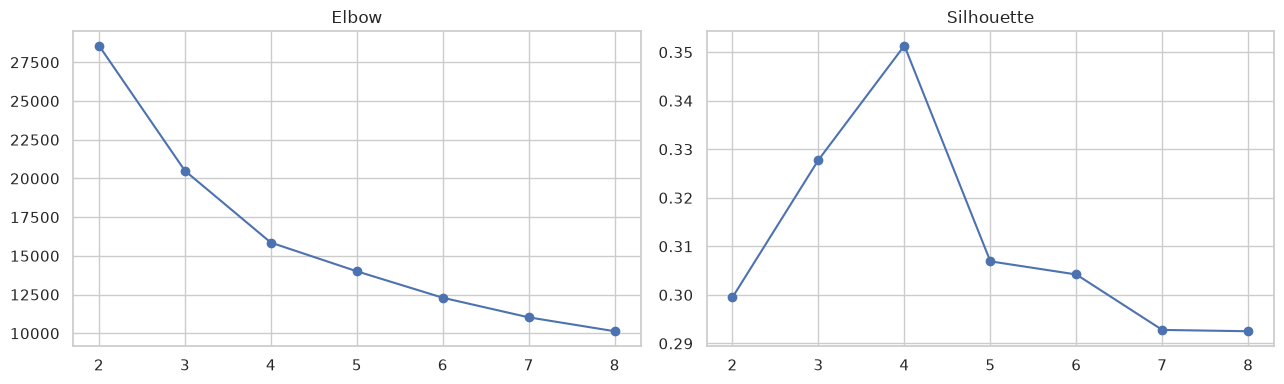

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); ax[0].plot(r['k_scores'].k, r['k_scores'].inertia, 'o-'); ax[0].set_title('Elbow'); ax[1].plot(r['k_scores'].k, r['k_scores'].silhouette, 'o-'); ax[1].set_title('Silhouette'); plt.tight_layout()

,n_customers,tenure_months,monthly_charges,clv,service_count,churn_probability,surv_prob_12m,actual_churn_rate,segment_label
cluster_id,,,,,,,,,
0,2226,27.11,28.44,280.69,1.79,0.13,0.85,0.13,Low-value customers
1,1705,53.93,88.42,980.55,6.59,0.13,0.92,0.12,High-value loyal
2,2158,11.46,76.93,799.79,3.97,0.57,0.88,0.57,High-value at-risk
3,954,53.40,79.71,363.71,5.67,0.16,0.37,0.17,"Mid-value, low-survival (watch list)"


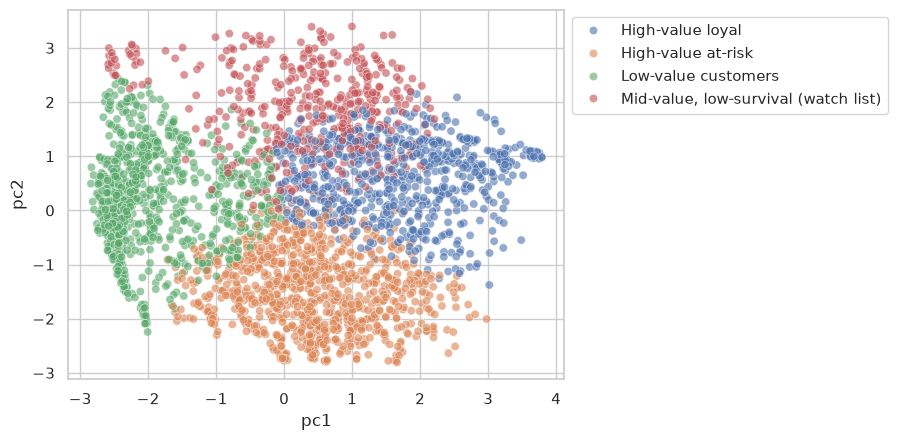

In [4]:
display(r['profile'].round(2))
s = r['segments']; sns.scatterplot(data=s.sample(3000, random_state=0), x='pc1', y='pc2', hue='segment_label', alpha=.6); plt.legend(bbox_to_anchor=(1,1))

Segment names are produced by rules applied to each cluster's mean CLV, churn probability, tenure and 12-month survival relative to the whole base, not assigned by hand.